In [34]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

In [35]:
df = pd.read_csv("student-mat.csv")

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [37]:
# check for duplicates
df[df.duplicated()]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3


There are no duplicates and no missing values in this dataset.

Next, we can check for and drop any invalid elements in the studytime or G3 columns. Studytime should be in the range of 1-4, and G3 in the range of 0-20 inclusive.

In [38]:
# drop students with invalid G3 grades
df.drop(df[0 > df['G3']].index)
df.drop(df[20 < df['G3']].index)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10


In [39]:
# drop students with invalid studytime scores
df.drop(df[1 > df['studytime']].index)
df.drop(df[4 < df['studytime']].index)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10


All of the G3 and studytime scores reported in this dataset are valid.

8 columns of binary data in this set are currently saved as strings. In the following section, I'm going to change those datatypes.

Affected Columns:
- schoolsup (Y/N)
- famsup (Y/N)
- paid (Y/N)
- activities (Y/N)
- nursery (Y/N)
- higher (Y/N)
- internet (Y/N)
- romantic (Y/N)

In [40]:
# convert strings to bool
df['schoolsup'] = df['schoolsup'].replace({'yes': True, 'no': False}).astype(bool)
df['famsup'] = df['famsup'].replace({'yes': True, 'no': False}).astype(bool)
df['paid'] = df['paid'].replace({'yes': True, 'no': False}).astype(bool)
df['activities'] = df['activities'].replace({'yes': True, 'no': False}).astype(bool)
df['nursery'] = df['nursery'].replace({'yes': True, 'no': False}).astype(bool)
df['higher'] = df['higher'].replace({'yes': True, 'no': False}).astype(bool)
df['internet'] = df['internet'].replace({'yes': True, 'no': False}).astype(bool)
df['romantic'] = df['romantic'].replace({'yes': True, 'no': False}).astype(bool)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    bool 
 16  famsup      395 non-null    bool 
 17  paid        395 non-null    bool 
 18  activities  395 non-null    bool 
 19  nursery     395 non-null    bool 
 20  higher      395 non-null    bool 
 21  inte

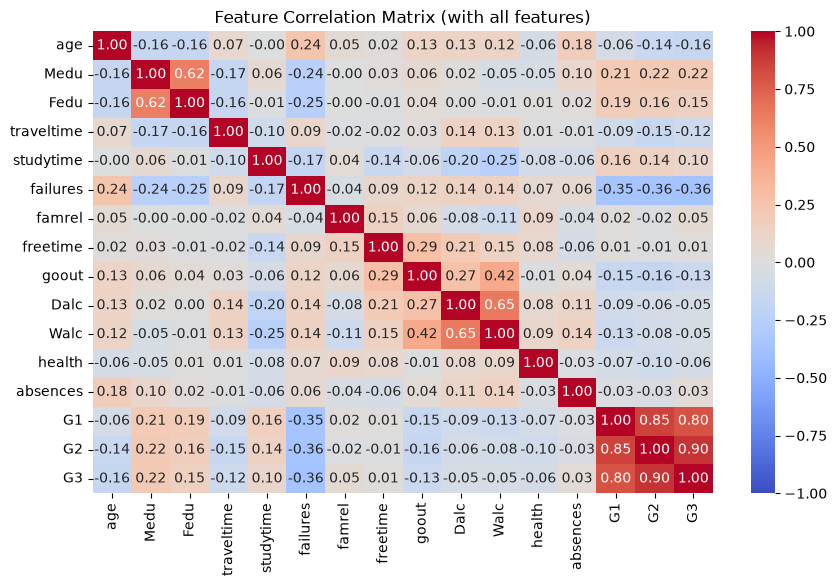

In [41]:
# create a heatmap to show the correlation between all of this dataset's numerical features
# NOTE: heatmaps are mostly good for showing linear relationships
plt.figure(figsize=(10, 6))
numeric_cols = df.select_dtypes(include=["number"])
sns.heatmap(numeric_cols.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin = -1, vmax=1)
plt.title("Feature Correlation Matrix (with all features)")
plt.show()